<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Introducción" data-toc-modified-id="Introducción-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Introducción</a></span></li><li><span><a href="#A-remangarse-las-manos" data-toc-modified-id="A-remangarse-las-manos-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>A remangarse las manos</a></span></li><li><span><a href="#Armado-del-dataset" data-toc-modified-id="Armado-del-dataset-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Armado del dataset</a></span></li><li><span><a href="#Features-(embeddings)" data-toc-modified-id="Features-(embeddings)-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Features (embeddings)</a></span><ul class="toc-item"><li><span><a href="#Imports" data-toc-modified-id="Imports-4.1"><span class="toc-item-num">4.1&nbsp;&nbsp;</span>Imports</a></span></li><li><span><a href="#Modelo-Inception-V3" data-toc-modified-id="Modelo-Inception-V3-4.2"><span class="toc-item-num">4.2&nbsp;&nbsp;</span>Modelo Inception V3</a></span></li><li><span><a href="#Generamos-los-embeddings" data-toc-modified-id="Generamos-los-embeddings-4.3"><span class="toc-item-num">4.3&nbsp;&nbsp;</span>Generamos los embeddings</a></span></li><li><span><a href="#Visualización-de-embeddings-en-3D" data-toc-modified-id="Visualización-de-embeddings-en-3D-4.4"><span class="toc-item-num">4.4&nbsp;&nbsp;</span>Visualización de embeddings en 3D</a></span></li><li><span><a href="#Visualización-de-embeddings-2D-con-PCA" data-toc-modified-id="Visualización-de-embeddings-2D-con-PCA-4.5"><span class="toc-item-num">4.5&nbsp;&nbsp;</span>Visualización de embeddings 2D con PCA</a></span></li></ul></li><li><span><a href="#Entrenando-nuestro-modelo" data-toc-modified-id="Entrenando-nuestro-modelo-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Entrenando nuestro modelo</a></span><ul class="toc-item"><li><span><a href="#Aumentación-de-datos" data-toc-modified-id="Aumentación-de-datos-5.1"><span class="toc-item-num">5.1&nbsp;&nbsp;</span>Aumentación de datos</a></span></li><li><span><a href="#Entrenamiento" data-toc-modified-id="Entrenamiento-5.2"><span class="toc-item-num">5.2&nbsp;&nbsp;</span>Entrenamiento</a></span></li><li><span><a href="#Evaluación-de-accuracy/loss-en-train-y-test" data-toc-modified-id="Evaluación-de-accuracy/loss-en-train-y-test-5.3"><span class="toc-item-num">5.3&nbsp;&nbsp;</span>Evaluación de accuracy/loss en train y test</a></span></li><li><span><a href="#Métricas-de-performance---evaluación-en-datos-no-vistos" data-toc-modified-id="Métricas-de-performance---evaluación-en-datos-no-vistos-5.4"><span class="toc-item-num">5.4&nbsp;&nbsp;</span>Métricas de performance - evaluación en datos no vistos</a></span></li><li><span><a href="#Thresholds" data-toc-modified-id="Thresholds-5.5"><span class="toc-item-num">5.5&nbsp;&nbsp;</span>Thresholds</a></span></li><li><span><a href="#Revisión-de-malos-resultados" data-toc-modified-id="Revisión-de-malos-resultados-5.6"><span class="toc-item-num">5.6&nbsp;&nbsp;</span>Revisión de malos resultados</a></span></li></ul></li></ul></div>

# Introducción

Sabemos que en el espacio uno pierde la orientación de lo que es arriba y abajo y por tanto ante la falta instrumentos que nos permitan guíarnos es importante poder reconocer objetos que nos den cierta ubicación. A partir de lo anterior y a modo ilustrativo proponemos generar un modelo de red neuronal capaz de identificar si dada una foto de un cuerpo celeste es o no el planeta tierra.


<table>
    <tr>
        <td>
        <img width="250" height="250"  src="https://i.imgur.com/qldQX6D.jpg" title="Tierra">
        </td>
        <td>
        <img width="250" height="250"  src="https://i.imgur.com/CXEm0kV.jpg" title="Luna">
        </td>
        <td>
        <img width="250" height="250"  src="https://i.imgur.com/ygVzUPH.jpg" title="Sol">
        </td>
         <td>
        <img width="300" height="300"  src="https://i.imgur.com/i3dxCvV.jpg" title="Asteroide">
        </td>
    </tr>

Si bien un humano a simple vista puede discernir entre un cuerpo celeste y otro, enseñarle a ejecutar dicha tarea a una computadora puede resultar dificíl. En lo que es el área de visión computacional y trabajo con imágenes las denominadas redes neuronales han sido de gran utilidad ya que en el proceso de entrenamiento permiten por un lado extraer propiedades importantes de las imágenes (que facilitan la tarea de reconocimiento) y por otro reducir los tiempos de procesamiento. 

Existen gran variedad de modelos de redes neuronales con diferente configuración y algunas de ellas ya cuentan con "información precargada", es decir son modelos que fueron entrenados con miles de imágenes (con lo que no empiezo mi trabajo desde 0) y me permite entonces continuar su entrenamiento o simplemente utilizarla tal cual está. Este concepto de utilizar algo pre-entrenado para continuarlo entrenando con más ejemplos se lo conoce como fine tuning y es un tipo de transfer learning.

Es así que en nuestro caso vamos utilizar un modelo de red neuronal conocido como [InceptionV3](https://arxiv.org/abs/1512.00567), que si bien no es el más reciente, aún demuestra tener una muy buena performance en tareas de clasificación de imágenes. A su vez si bien podríamos entrenar dicha red neuronal con los escasos ejemplos que tenemos vamos a utilizar un preentrenamiento a partir de [ImageNet](http://www.image-net.org/). 

¿Qué es ImageNet? Bueno, simplemente un dataset muuuy grande de imágenes con sus respectivas anotaciones a través de varias categorías, alrededor de este dataset es que año a año se celebran competiciones para encontrar soluciones a problemas de visión computacional, actualmente se encuentra un challenge disponible en [Kaggle](https://www.kaggle.com/c/imagenet-object-localization-challenge). 

A continuación mostramos algunas imágenes del dataset en el ILSVRC (ImageNet Large Scale Visual Recognition Challenge) de 2015:

<img src="https://3qeqpr26caki16dnhd19sv6by6v-wpengine.netdna-ssl.com/wp-content/uploads/2017/08/Sample-of-Images-from-the-ImageNet-Dataset-used-in-the-ILSVRC-Challenge.png" alt="Sample of Images from the ImageNet Dataset used in the ILSVRC Challenge" width="1000" height="1000">

Algunas estadísticas de ImageNet

<table class="table-stats" style="width: 500px">
<tbody><tr>
<td width="25%"><b>High level category</b></td>
<td width="20%"><b># synset (subcategories)</b></td>
<td width="30%"><b>Avg # images per synset</b></td>
<td width="25%"><b>Total # images</b></td>
</tr>

<tr><td>amphibian</td><td>94</td><td>591</td><td>56K</td></tr>

<tr><td>animal</td><td>3822</td><td>732</td><td>2799K</td></tr>

<tr><td>appliance</td><td>51</td><td>1164</td><td>59K</td></tr>

<tr><td>bird</td><td>856</td><td>949</td><td>812K</td></tr>

<tr><td>covering</td><td>946</td><td>819</td><td>774K</td></tr>

<tr><td>device</td><td>2385</td><td>675</td><td>1610K</td></tr>

<tr><td>fabric</td><td>262</td><td>690</td><td>181K</td></tr>

<tr><td>fish</td><td>566</td><td>494</td><td>280K</td></tr>

<tr><td>flower</td><td>462</td><td>735</td><td>339K</td></tr>

<tr><td>food</td><td>1495</td><td>670</td><td>1001K</td></tr>

<tr><td>fruit</td><td>309</td><td>607</td><td>188K</td></tr>

<tr><td>fungus</td><td>303</td><td>453</td><td>137K</td></tr>

<tr><td>furniture</td><td>187</td><td>1043</td><td>195K</td></tr>

<tr><td>geological formation</td><td>151</td><td>838</td><td>127K</td></tr>

<tr><td>invertebrate</td><td>728</td><td>573</td><td>417K</td></tr>

<tr><td>mammal</td><td>1138</td><td>821</td><td>934K</td></tr>

<tr><td>musical instrument</td><td>157</td><td>891</td><td>140K</td></tr>


<tr><td>plant</td><td>1666</td><td>600</td><td>999K</td></tr>

<tr><td>reptile</td><td>268</td><td>707</td><td>190K</td></tr>

<tr><td>sport</td><td>166</td><td>1207</td><td>200K</td></tr>

<tr><td>structure</td><td>1239</td><td>763</td><td>946K</td></tr>

<tr><td>tool</td><td>316</td><td>551</td><td>174K</td></tr>

<tr><td>tree</td><td>993</td><td>568</td><td>564K</td></tr>

<tr><td>utensil</td><td>86</td><td>912</td><td>78K</td></tr>

<tr><td>vegetable</td><td>176</td><td>764</td><td>135K</td></tr>

<tr><td>vehicle</td><td>481</td><td>778</td><td>374K</td></tr>

<tr><td>person</td><td>2035</td><td>468</td><td>952K</td></tr>

</tbody></table>

# A remangarse las manos

Empezaremos ahora si con la parte práctica para ver si podemos crear un modelo capaz de poder reconocer si una foto es o no el planeta tierra, para ello utilizaremos una librería de alto nivel llamada [Keras](https://keras.io/) que nos hará más fácil la vida a la hora de construir, entrenar y utilizar nuestros modelos. De esta librería también estaremos utilizando algunas funciones para el manejo de imágenes solo para mantener la simpleza, si bien existen otras librerías igual de útiles como [openCV](https://docs.opencv.org/master/) o [Pillow](https://pillow.readthedocs.io/en/stable/).

# Armado del dataset

Como ya lo hemos mencionado la base fundamental para un buen modelo de machine learning son los datos con los que se entrena, dicho de una manera más ruda, si uno entrena con basura lo que va a tener después será también basura. Es así que empezaremos por armar nuestro pequeño dataset para la clasificación entre tierra y no tierra. 

Primero debemos observar que en la carpeta `space_dataset` vamos a encontrar varias subcarpetas con algunas categorías, en nuestro caso solamente vamos a considerar `moon`, `sun`, `jupiter` y por supuesto `earth`. En primera instancia vamos a crear la siguiente estructura de carpetas:


    train/
    ├── earth/
    │   ├── earth-1.jpeg
    │   ├── ...
    │   └── earth-n.jpeg
    └── no_earth/
        ├── sun-1.jpeg
        ├── ...
        ├── sun-n.jpeg
        ├── moon-1.jpeg
        ├── ...
        ├── moon-n.jpeg
        ├── jupiter-1.jpeg
        ├── ...
        └── jupiter-n.jpeg
    
    test/
    ├── earth/
    │   └── ...
    └── no_earth/
        └── ...
        
    eval/
    ├── earth/
    │   └── ...
    └── no_earth/
        └── ...
  

La idea es entonces colocar todas las imágenes (y solo las imágenes) de la tierra dentro de `earth`, la cual será nuestra clase positiva, es decir aquellos ejemplos que son tierra, y las imagenes correspondientes a las otras carpetas las vamos a unificar en la carpeta `no_earth`, que será nuestra clase negativa, es decir todo aquello que no es tierra. 

Del conjunto de fotos dentro de `train` vamos a seleccionar 6 de la carpeta `earth` y 17 de `no_earth` (que al menos haya un ejemplo de cada una de las clases) que moveremos a sus respectivas carpetas en `test` la idea es que usemos estas imágenes para validar que nuestro entrenamiento no esté sobreajustando a los datos que mostramos a la red para entrenarla.

Tendremos así unas 50 imágenes de la tierra para entrenar contra 100 del resto de los cuerpos celestes, es importante destacar que generalmente este problema de desbalanceo entre clases puede presentar complicaciones debido a las implicacancias de equivocarse en la predicción de una clase u otra, existen técnicas que permiten asignar pesos a la hora de cometer un error para equilibrar dicha inequidad.

A su vez viendo la cantidad de imágenes que tenemos en total parece un número demasiado pequeño, veremos también más adelante opciones para aumentar dicho conjunto de datos a traves de técnicas de aumentación (data augmentation) que a traves de por ejemplo rotación, flipeo, entre otras cosas, permiten generar cientos de imágenes a partir de una sola.

En la carpeta de `eval` el plan es que busquemos algunas imágenes de internet para colocar dentro de earth del mismo estilo que existen en train, lo mismo para no_earth. La idea es que con estas imágenes luego vamos a evaluar a través de métricas cuál es la performance de nuestro modelo en datos aún no vistos.

# Features (embeddings)

Hace unos momentos hablamos de que las redes neuronales son capaces de extraer propiedades importantes de las imágenes y que dichas propiedades hacen más sencillo el aprendizaje y a su vez reducen los tiempos de procesamiento. Por esta razón es que hacemos un pequeña pausa en este tema para comprenderlo mejor :)

Es así que veremos como poder a partir de una imagen obtener su representación vectorial, es decir su lista de features. Para ello haremos uso del modelo de InceptionV3 pero en este caso no lo usaremos para clasificar sino que iremos a un paso previo de su ejecución final y pediremos que nos dé la lista de features a la cual arriba previo a su clasificación.

## Imports

Empezamos importando algunas cosas necesarias para el uso de InceptionV3 a través de keras y algunas otras cositas, entre ellas [numpy](https://numpy.org/), una librería muy performante para el manejo de arrays n-dimensionales con varias utilidades.

In [0]:
# modelo de InceptionV3 y función para el procesamiento del archivo.
from keras.applications.inception_v3 import InceptionV3
from keras.applications.inception_v3 import preprocess_input

# para el manejo de imágenes
from keras.preprocessing import image

# para el manejo de n-arrays
import numpy as np

## Modelo Inception V3

A continuación haremos uso de InceptionV3 preentrenado con ImageNet para generar los embeddings de las imágenes, para ello instanciaremos un objeto de InceptionV3 y a través del parámetro `weights` estableceremos que se usen los pesos entrenados con ImageNet. Esto lo que hace por un lado es descargarnos los pesos a nuestra máquina para poder luego cargarlos en la red y poder utilizar nuestra red pre-entrenada. También haremos uso del parámetro `include_top` que lo pondremos en falso para que la capa de salida (la que realiza la clasificación) no se aplique.

In [0]:
model = InceptionV3(weights='imagenet', include_top=False)

Una vez finalizada la instanciación de nuestro modelo a través del método `summary` podemos tener detalles de su arquitectura, obviamente explicar cada una de las partes que lo componene está muy por fuera del alcance del taller pero no deja de ser un aspecto interesante a mostrar.

In [0]:
print(model.summary())

__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_2 (InputLayer)            (None, None, None, 3 0                                            
__________________________________________________________________________________________________
conv2d_95 (Conv2D)              (None, None, None, 3 864         input_2[0][0]                    
__________________________________________________________________________________________________
batch_normalization_95 (BatchNo (None, None, None, 3 96          conv2d_95[0][0]                  
__________________________________________________________________________________________________
activation_95 (Activation)      (None, None, None, 3 0           batch_normalization_95[0][0]     
__________________________________________________________________________________________________
conv2d_96 

Hay sitios como [tensorspace](https://tensorspace.org/html/playground/index.html) que permiten visualizar lo que va sucediendo con la imagen a medida que pasa por las capas de una red, es posible analizar varios modelos de redes neuronales.

## Generamos los embeddings

In [0]:
# definimos por ejemplo la ruta a una de las imágenes
img_path = './space_dataset/earth/1. earth_western_hemisphere.jpg.jpeg'

# cargamos la imagen con la ayuda del método load_img pasándole la ruta de la imagen
# y al mismo tiempo haciendo un resize de la misma, en este caso al tamaño por defecto
# que tiene la red InceptionV3: (299:img_height, 299:img_width)
img = image.load_img(img_path, target_size=(299, 299))

# convertimos el objeto imagen que obtuvimos en el paso anterior en un array, no es casualidad que
# nombremos x a la variable.. ¿a qué les suena? ... f(x) = y
x = image.img_to_array(img)

# vemos la forma que tiene el array
print(f"shape de la imagen original: {x.shape}")

# expandimos en uno la dimensión de dicho array, esto es: en vez de tener un n-array 
# representando la imagen, tenemos una lista de un único elemento que es dicho n-array de la imagen.
# Esto debido a como la red neuronal está esperando el shape del input (?, 299, 299, 3).
x = np.expand_dims(x, axis=0)

# vemos la forma que tiene el array luego de agregar una nueva dimensión
print(f"shape de la imagen luego de agregarle una nueva dimensión: {x.shape}")

# utilizamos la función de preprocesamiento de la imagen para coincidir con lo esperado por 
# la red de InceptionV3. El preprocesamiento podría ser por ejemplo escalar todos los valores, 
# o restarle a todos la media entre otras transformaciones matemáticas. En el caso de 
# Inception V3 necesitamos realizar un preprocesamiento tal que los valores del n-array 
# estén entre 0 y 1.
x = preprocess_input(x)

# le pedimos al modelo que infiera el resultado a partir de lo trabajado.
features = model.predict(x)

In [0]:
# para visualizar una muuuy ínfima parte del n-array.
# si queremos ver todo o lo que la notebook llegue a mostrar alcanza 
# simplemente con ejecutar "features" sin los corchetes e índices.
features[:,2:4,2:4,0:10]

array([[[[0.46245518, 0.        , 0.        , 0.42805555, 0.        ,
          0.        , 0.24484354, 0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        , 0.2995228 , 0.        ,
          0.        , 0.        , 0.        , 0.        , 0.4342705 ]],

        [[0.6764786 , 0.        , 0.        , 0.        , 0.        ,
          0.        , 0.09341252, 1.0102308 , 0.        , 0.7724183 ],
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        , 0.        , 0.46435001, 0.45872045, 1.9852014 ]]]],
      dtype=float32)

In [0]:
# para ver la forma del n-array podemos utilizar la propiedad shape que poseen los numpy arrays
features.shape

(1, 8, 8, 2048)

Es entonces que podríamos llegar a generar los embeddings para todas nuestras imágenes, a continuación vamos a mostrar un código para obtener dichos embeddings y almacenar esa información en un csv (un archivo delimitado por comas) para poder luego visualizar las imágenes en una representación vectorial en 3D utilizando una herramienta llamada tensorboard.

In [0]:
# definimos algunos imports y funciones auxiliares para hacer más fácil la programación

# os es una librería para trabajar con el sistema de archivos
import os
from os import listdir, makedirs
from os.path import isfile, join, isdir, exists

# definimos una función para dado un archivo y un mensaje, guardar dicho mensaje en el archivo.
def write2file(file_name: str, msg: str):
    file_path = f'SUMMARY/{file_name}'
    if not exists('SUMMARY'):
        makedirs('SUMMARY')

    with open(file_path, mode="a") as f:
        f.write(msg + '\n')

# dada una ruta a una carpeta devolver todos directorios (y solamente directorios) de esa carpeta.
def get_dirs(dir_path):
    return [d for d in listdir(dir_path) if isdir(join(dir_path, d))]

# dada una ruta a una carpeta devolver todos archivos (y solamente archivos) de ese directorio.
def get_dir_files(dir_path: str):
    return [f for f in listdir(dir_path) if isfile(join(dir_path, f))]

# para esta función utilizamos el código visto anteriormente y aprovechamos que tenemos
# la variable model cargada en memoria.
def get_embeddings(image_path: str) -> np.array:
    img = image.load_img(image_path, target_size=(299, 299))

    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)

    return model.predict(x)
    

In [0]:
# definimos un path a donde está nuestra carpeta con el dataset original
INPUT_FOLDER = "/home/zurdozen/Projects/pinos/space_dataset"

# nombre que va a tener el archivo csv
CSV_FILE = "space.csv"

# vamos a incluir únicamente las carpetas que utilizaremos para el train
folds = ['moon', 'sun', 'jupiter', 'earth']

# escribimos el cabezal del csv
write2file(CSV_FILE, "fold;image_file;embeddings")

# recorremos una a una las carpetas obteniendo las imagenes, generando los embeddings y 
# guardando esa información en el archivo csv
for fold in folds:
    images = get_dir_files(join(INPUT_FOLDER, fold))
    
    print(f"Processing {fold}...")
    images_len = len(images)
    for idx, img in enumerate(images):
        print(f" >> Generating embeddings for image {idx + 1}/{images_len}")
        
        src = join(INPUT_FOLDER, fold, img)
        embeddings = get_embeddings(src)
        
        # los embeddings tienen un shape (1, 8, 8, 2048) guardaremos esta matriz en forma de 
        # un array flatten lo que nos da un shape (131072,) (1 x 8 x 8 x 2048)
        obj = f'"{fold}";"{img}";"{",".join([ str(emb) for emb in embeddings.ravel(order="C")])}"'
        write2file(CSV_FILE, obj)

Processing moon...
 >> Generating embeddings for image 1/69
 >> Generating embeddings for image 2/69
 >> Generating embeddings for image 3/69
 >> Generating embeddings for image 4/69
 >> Generating embeddings for image 5/69
 >> Generating embeddings for image 6/69
 >> Generating embeddings for image 7/69
 >> Generating embeddings for image 8/69
 >> Generating embeddings for image 9/69
 >> Generating embeddings for image 10/69
 >> Generating embeddings for image 11/69
 >> Generating embeddings for image 12/69
 >> Generating embeddings for image 13/69
 >> Generating embeddings for image 14/69
 >> Generating embeddings for image 15/69
 >> Generating embeddings for image 16/69
 >> Generating embeddings for image 17/69
 >> Generating embeddings for image 18/69
 >> Generating embeddings for image 19/69
 >> Generating embeddings for image 20/69
 >> Generating embeddings for image 21/69
 >> Generating embeddings for image 22/69
 >> Generating embeddings for image 23/69
 >> Generating embedding

Deberíamos tener entonces nuestro archivo `space.csv` generado con los embeddings para cada imagen.

In [0]:
# el '!' nos permite ejecutar código como si estuviéramos en una consola. 
# El comando "ls" lista los elementos dentro del directorio.
!ls "./SUMMARY/"

space.csv


## Visualización de embeddings en 3D

Pasemos ahora a visualizar dichos embeddings en un espacio en 3 dimensiones, para ellos haremos uso de otra librería ampliamente usada para modelos de machine learning de denominada [tensorflow](https://www.tensorflow.org/) junto con otra herramienta llamada tensorboard para visualización de vectores. Destacar también el uso de [pandas](https://pandas.pydata.org/) una librería que permite manejar datasets de forma sencilla y performante. 

Ya que estaremos visualizando vectores en el espacio no podemos dejar de hablar  de algunas técnicas de reducción de dimensionalidad que comentaremos de manera muy general. 

Empecemos por importar lo que vamos a necesitar.

Para lo que es el ploteo de gráficas más adelante utilizaremos la librería de [matplotlib](https://matplotlib.org/) que es una de las más usadas para graficar.

In [0]:
# importamos la librería de tensorflow y la función projector para ayudarnos a  
# generar los archivos que necesitamos para la visualización.
import tensorflow as tf
from tensorflow.contrib.tensorboard.plugins import projector

# importamos pandas para cargar y trabajar el arhivo csv.
import pandas as pd

# vamos a importar la librería de matplotlib para poder realizar gráficas
import matplotlib.pyplot as plt

Carguemos el array generado y obtengamos los embeddings de cada imagen.

In [0]:
# leemos el archivo csv con pandas indicando que los elementos están separados por ';'
df = pd.read_csv(join("./SUMMARY/", CSV_FILE), sep=';')
# damos una revisión a los primeros elementos del dataframe
df.head()

,fold,image_file,embeddings
0,moon,1. full-moon.jpg.jpeg,"1.0318073,0.63188696,0.9248544,0.0,0.0,0.39083..."
1,moon,20. https%3a%2f%2fblogs-images.forbes.com%2fjo...,"1.2693824,0.0,0.0,0.0,0.0,1.6600324,0.35390013..."
2,moon,35. sturgeon-moon-2019_pt6g.910.jpg.jpeg,"0.0,0.6405549,0.95020473,0.0,0.0,0.7364101,0.7..."
3,moon,86. lead_720_405.jpg.jpeg,"0.25317812,0.6829958,0.8176595,0.0,0.0,0.0,0.0..."
4,moon,58. spzgh5xkg2pev8jfzww3fo.jpg.jpeg,"0.0,0.0,1.2373132,0.0,0.0,0.5930684,0.0,0.0,0...."


Ahora transformaremos los embeddings que fueron almacenados como un string de nuevo a un array y obtenemos una lista de dichos vectores.

In [0]:
# sobreescribimos la columna embeddings string por embeddings array (numpy).
df['embeddings'] = df['embeddings'].apply(lambda x: np.array([float(str_dim) for str_dim in x.split(',')], dtype=np.float32))

# obtenemos una lista (array) de embeddings con shape (176, 131072), es decir
# 176 imágenes donde cada una posee un array de 131072 elementos.
vectors = np.array(df['embeddings'].tolist())

Generamos ahora un archivo de metadata con las etiquetas de cada embedding, utilizaremos la carpeta y el nombre del archivo para generar dichas labels.

Previamente en nuestra solución vamos a necesitar crear una carpeta de nombre `project-tensorboard` donde guardaremos los archivos de etiquetas y de embeddings para visualizar en tensorboard.

In [0]:
PATH = os.getcwd()
LOG_DIR = join(PATH, 'project-tensorboard/logdir-1/')

# si no existe el directorio lo creamos.
if not exists(LOG_DIR):
    makedirs(LOG_DIR)

metadata = join(LOG_DIR, 'df_labels.tsv')

with open(metadata,'w') as f:
    f.write("Index\tLabel\n")
    for index,(file, label) in enumerate(zip(df.image_file, df.fold)):
        f.write(f'{label} - {file}\t{label}\n')

embs_tsv = join(LOG_DIR, 'df_embeddings.tsv')

with open(embs_tsv,'w') as f:
    for dims in vectors:
        f.write('\t'.join([str(dim) for dim in dims])+'\n')

Para ver los vectores en 3D iremos al sitio de https://projector.tensorflow.org/ donde podemos subir los archivos recién creados y jugar un poco con los diferentes algoritmos y sus parámetros.

Una vez en el sitio iremos hacia el botón de Load y cargaremos el archivo `df_embeddings.tsv` en la primera parte y el archivo de `df_labels.csv` en la segunda. Una vez cargados ambos archivos hacemos click fuera del modal y tendremos suficiente para entretenernos :)

![image.png](https://i.imgur.com/gzggMXI.png)

Repasando un poco entonces estas técnicas de reducción de dimensionalidad que estuvimos viendo intentan poder explicar la misma variabilidad de los datos pero reduciendo considerablemente el número de dimensiones. También podemos aplicar dichas técnicas de manera manual como veremos a continuación.

## Visualización de embeddings 2D con PCA

En este caso vamos a aplicar PCA (principal component analysis) sobre el conjunto de vectores y luego los graficaremos. Para el uso de PCA vamos a utilizar la librería de [scikit-learn](https://scikit-learn.org/stable/) que nos permitirá implementar de manera sencilla la reducción de dimensionalidad.

Primero que nada pasemos a importar todo aquello que necesitamos.

In [0]:
# clase PCA para aplicar sobre los vectores.
from sklearn.decomposition import PCA

# PCA es sensible a la variabilidad de los datos por lo que estandarizaremos los mismos previo a aplicar la 
# reducción de dimensionalidad. En el sitio de scikit-learn explica en detalle esto que mencionamos:
# https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html#sphx-glr-auto-examples-preprocessing-plot-scaling-importance-py
from sklearn.preprocessing import StandardScaler

Pasemos entonces a estandarizar los vectores y aplicar PCA.

In [0]:
# Estandarizando los vectores
 vectors_std = StandardScaler().fit_transform(vectors)

Veamos la diferencia

In [0]:
vectors[0:10]

array([[1.0318073 , 0.63188696, 0.9248544 , ..., 0.        , 0.        ,
        0.        ],
       [1.2693824 , 0.        , 0.        , ..., 1.4773798 , 2.842085  ,
        0.7818703 ],
       [0.        , 0.6405549 , 0.95020473, ..., 1.4063658 , 0.        ,
        0.        ],
       ...,
       [0.24377698, 0.        , 0.        , ..., 0.49454254, 0.6500744 ,
        0.8945779 ],
       [0.8921039 , 0.5500163 , 0.00784835, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.87239325, 0.        ,
        0.21879545]], dtype=float32)

In [0]:
vectors_std[0:10]

array([[ 2.613424  ,  1.1988258 ,  1.6462177 , ..., -0.511728  ,
        -0.528287  , -0.5147984 ],
       [ 3.3189573 , -0.710206  , -0.48361495, ...,  2.5184257 ,
         4.6108923 ,  1.7661784 ],
       [-0.4507627 ,  1.225013  ,  1.7045966 , ...,  2.3727736 ,
        -0.528287  , -0.5147984 ],
       ...,
       [ 0.27318853, -0.710206  , -0.48361495, ...,  0.50259477,
         0.64720535,  2.094984  ],
       [ 2.198543  ,  0.95148134, -0.46554112, ..., -0.511728  ,
        -0.528287  , -0.5147984 ],
       [-0.4507627 , -0.710206  , -0.48361495, ...,  1.2775788 ,
        -0.528287  ,  0.12350095]], dtype=float32)

In [0]:
# instanciamos PCA, en este caso simplemente le decimos que reduzca la dimensionalidad a 2, existen
# otros parámetros para instanciar PCA dependiendo lo que uno necesite hacer.
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(vectors_std)

# consultamos para saber qué tanta varianza explican los datos
pca.explained_variance_ratio_

array([0.04799372, 0.0367917 ], dtype=float32)

In [0]:
principalComponents.shape

(176, 2)

En el paso anterior le dijimos a pca que redujera la dimensionalidad a 2 dimensiones y luego consultando los resultados de varianza explicada vemos que nuestras dos dimensiones explican únicamente el 7% (4% en pca uno + 3 en pca dos), lo que es un número bajísimo y obviamente nunca serían de utilidad. De todas formas grafiquemos los datos en función de dichas dimensiones.

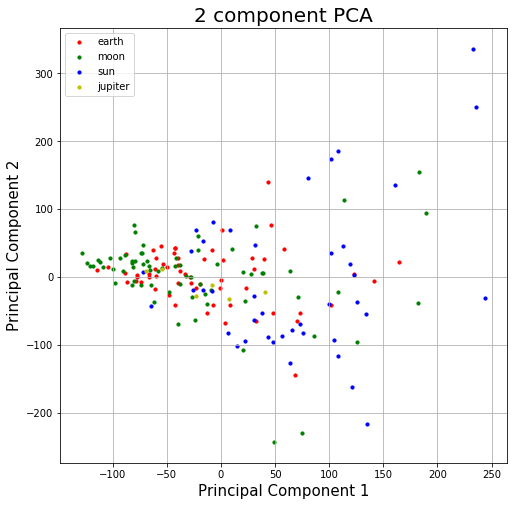

In [0]:
# creamos un objeto y seteamos propiedades para la visualización.
fig = plt.figure(figsize = (8,8))
ax = fig.add_subplot(1,1,1) 
ax.set_xlabel('Principal Component 1', fontsize = 15)
ax.set_ylabel('Principal Component 2', fontsize = 15)

ax.set_title('2 component PCA', fontsize = 20)

# ploteamos los datos en función de las dimensiones.
targets = ['earth', 'moon', 'sun', 'jupiter']
colors = ['r', 'g', 'b', 'y']
for target, color in zip(targets,colors):
    indicesToKeep = df['fold'] == target    
    ax.scatter(principalComponents[indicesToKeep][:,0:1]
               , principalComponents[indicesToKeep][:,1:2]
               , c = color
               , s = 10)
ax.legend(targets)
ax.grid()

# Entrenando nuestro modelo

Ya con un poquito más de background pasaremos a entrenar nuestro modelo, repasando un poco la idea es utilizar un modelo conocido como InceptionV3 ya preentrenado con ImageNet. Lo que haremos para refinar este modelo será agregar nuevas capas que serán las que aprenderán en definitiva, esto se debe a que mantendremos congelados los pesos de la arquitectura de InceptionV3. 

Haciendo un poquito de memoria lo que estaremos haciendo aquí es lo que se conoce como fine tuning que es un tipo de transfer learning.

In [0]:
from keras.models import Model
from keras.layers import Dense, GlobalAveragePooling2D
from keras import backend as K

In [0]:
# creamos la base del modelo a partir de inception v3 preentrenado con ImageNet y no colocaremos la capa final.
base_model = InceptionV3(weights='imagenet', include_top=False)

# agregamos algunos tensores más
x = base_model.output
x = GlobalAveragePooling2D()(x)

# agregamos una capa fully-connected
x = Dense(1024, activation='relu')(x)

# y por último una capa logística para obtener nuestras 2 clases
predictions = Dense(1, activation='sigmoid')(x)

# creamos el modelo que vamos a entrenar teniendo como entrada inception v3 con las capaz que se agregaron.
model = Model(inputs=base_model.input, outputs=predictions)

# Como ya mencionamos vamos a estar entrenando únicamente las capas que agregamos
# por tanto vamos a freezar (congelar) los pesos de todas las capas de InceptionV3
for layer in base_model.layers:
    layer.trainable = False

# por último compilamos nuestro modelo.
model.compile(optimizer='adam', loss='binary_crossentropy',metrics=['accuracy'])

W0914 17:16:37.957258 139841241149568 deprecation_wrapper.py:119] From /home/zurdozen/.pyenv/versions/jupyter-nb/lib/python3.6/site-packages/keras/optimizers.py:790: The name tf.train.Optimizer is deprecated. Please use tf.compat.v1.train.Optimizer instead.

W0914 17:16:37.976791 139841241149568 deprecation.py:323] From /home/zurdozen/.pyenv/versions/jupyter-nb/lib/python3.6/site-packages/tensorflow/python/ops/nn_impl.py:180: add_dispatch_support.<locals>.wrapper (from tensorflow.python.ops.array_ops) is deprecated and will be removed in a future version.
Instructions for updating:
Use tf.where in 2.0, which has the same broadcast rule as np.where


In [0]:
print(model.summary())

__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_3 (InputLayer)            (None, None, None, 3 0                                            
__________________________________________________________________________________________________
conv2d_189 (Conv2D)             (None, None, None, 3 864         input_3[0][0]                    
__________________________________________________________________________________________________
batch_normalization_189 (BatchN (None, None, None, 3 96          conv2d_189[0][0]                 
__________________________________________________________________________________________________
activation_189 (Activation)     (None, None, None, 3 0           batch_normalization_189[0][0]    
__________________________________________________________________________________________________
conv2d_190

## Aumentación de datos

Habíamos comentado a la hora del armado del dataset que nuestros ejemplos para entrenar eran algo insuficientes por lo que podíamos intentar técnicas de aumentación de datos y es lo que vamos a aprender a aplicar.

In [0]:
# importaremos la clase ImageDataGenerator que nos permite definir 
# ciertas operaciones/transformaciones sobre las imágenes para generar más ejemplos.
from keras.preprocessing.image import ImageDataGenerator

# luego instanciamos el objeto escalando los pixels de la foto, 
# generando rotaciones random entre 0º y 20º grados e
# invirtiendo la imagen de derecha a izquierda y de arriba a abajo.
datagen = ImageDataGenerator(rescale=1./255, rotation_range=20, horizontal_flip=True, vertical_flip=True)

#definimos algunas variables
batch_size = 25
img_width = img_height = 299

# implementamos un generador para train y test con las especificaciones del image data generator,
# especificando que se tomarán batches de a 25 imágenes y que las mismas deben estar
# redimensionadas a 299x299 y que utilizaremos class mode binary ya que estamos ante
# una clasificación binaria, es decir, ¿hay tierra a la vista? ¿si o no?
train_generator = datagen.flow_from_directory(
        "corpus/train/",
        target_size=(img_height, img_width),
        batch_size=batch_size,
        class_mode='binary',
        classes= ['no_earth','earth'])

test_generator = datagen.flow_from_directory(
        "corpus/test/",
        target_size=(img_height, img_width),
        batch_size=batch_size,
        class_mode='binary',
        classes= ['no_earth','earth'])

Found 153 images belonging to 2 classes.
Found 23 images belonging to 2 classes.


In [0]:
# para determinar cuales serán 
train_generator.class_indices

{'no_earth': 0, 'earth': 1}

## Entrenamiento

In [0]:
# salvamos la historia del training en la variable stat para poder 
# observar el comportamiento del accuracy y el loss de nuestros dataset de
# train y test. En este caso vamos a entrenar usando el generator de imágenes
# de train y supervisaremos dicho entrenamiento a través del generator de test.
# En este caso vamos a entrenar con 5 épocas de 10 pasos cada una.
stats = model.fit_generator(
        train_generator,
        steps_per_epoch=10,
        epochs=5,
        validation_data=test_generator,
        validation_steps=10)

# salvamos los pesos de nuestra red para si en algún momento queremos volver 
# a entrenar, no necesitamos hacerlo desde cero, podemos cargar los pesos guardados en 
# nuestro modelo y continuar entrenando desde allí.
save_model_weights = False
if save_model_weights:
    model.save_weights('first_try.h5') 

Epoch 1/5
10/10 [==============================] - 48s 5s/step - loss: 2.3365 - acc: 0.4593 - val_loss: 0.8173 - val_acc: 0.7391
Epoch 2/5
10/10 [==============================] - 48s 5s/step - loss: 0.9701 - acc: 0.2542 - val_loss: 0.6387 - val_acc: 0.7391
Epoch 3/5
10/10 [==============================] - 47s 5s/step - loss: 0.6755 - acc: 0.6757 - val_loss: 0.5460 - val_acc: 0.7391
Epoch 4/5
10/10 [==============================] - 48s 5s/step - loss: 0.5773 - acc: 0.6868 - val_loss: 0.5497 - val_acc: 0.7391
Epoch 5/5
10/10 [==============================] - 46s 5s/step - loss: 0.5447 - acc: 0.8284 - val_loss: 0.5040 - val_acc: 0.7696


## Evaluación de accuracy/loss en train y test

En esta sección la idea es mirar un poco la evolución de nuestro entrenamiento y analizar su comportamiento a lo largo del proceso, muchas veces podemos encontrar ciertas pautas para saber si es necesario seguir entrenando o por otro lado si estamos sobreajustando demasiado.

dict_keys(['val_loss', 'val_acc', 'loss', 'acc'])


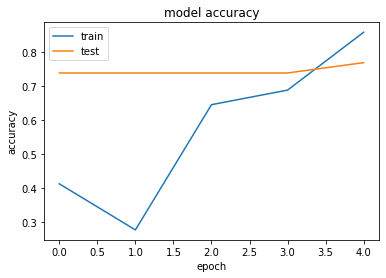

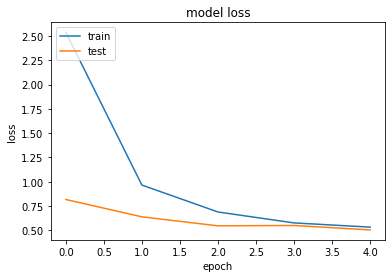

In [0]:
# listamos la información del entrenamiento
print(stats.history.keys())

# sumarizamos los stats de accuracy
plt.plot(stats.history['acc'])
plt.plot(stats.history['val_acc'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

# sumarizamos los stats de loss
plt.plot(stats.history['loss'])
plt.plot(stats.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

## Métricas de performance - evaluación en datos no vistos

La idea ahora es poder evaluar qué tan bien está funcionando nuestro modelo, es decir, si hoy por hoy fueramos a lanzar nuestro cohete al espacio y empezaramos a sacar fotos satelitales y a querer orientarnos a partir de ellas, ¿Qué certezas tendríamos? ¿Estamos detectando correctamente? bueno la siguiente sección pretende darnos una idea de ello.

In [0]:
# si recordamos nuestra labels son 'earth' y 'no_earth'
labels = ['earth', 'no_earth']

# definimos una función auxiliar para que nos facilite las inferencias del modelo.
def get_prediction(image_path: str) -> np.array:
    img = image.load_img(image_path, target_size=(299, 299))

    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)
    
    # los resultados van a ser una probabilidad de qué tan 
    # seguro está el modelo de que lo que vio sea tierra
    result = model.predict(x)

    return result

In [0]:
# definimos un path a donde está nuestra carpeta con el dataset de evaluación
EVAL_FOLDER = "corpus/eval/"

# definimos lo que se conoce como punto de corte, es decir si la confianza devuelta
# por el modelo supera dicho valor, entonces lo consideramos como una predicción
# positiva, si el valor es menor entonces una predicción negativa.
threshold = 0.5

# recorremos una a una las carpetas obteniendo las imagenes, y generando las predicciones.
eval_Xs = []
eval_Ys = []
eval_preds = []
files = []
folds = get_dirs(EVAL_FOLDER)
for fold in folds:
    images = get_dir_files(join(EVAL_FOLDER, fold))
    
    print(f"Processing {fold}...")
    images_len = len(images)
    for idx, img in enumerate(images):
        print(f" >> Checking image {img} ({idx + 1}/{images_len})")
        
        src = join(EVAL_FOLDER, fold, img)
        files.append(src)
        
        result = get_prediction(src)[0][0]
        
        # generamos una lista con las probabilidades devueltas por el modelo para cada imagen.
        eval_preds.append(result)
        
        # generamos nuestra lista de y_true, es decir la etiqueta de quebería tener la foto.
        eval_Xs.append(1 if fold == "earth" else 0)
        
        # generamos nuestra lista de y_pred, es decir la etiqueta que nos dio la predicción.
        eval_Ys.append(1 if result > 0.5 else 0)

files = np.array(files)
eval_preds = np.array(eval_preds)
eval_Xs = np.array(eval_Xs)
eval_Ys = np.array(eval_Ys)

Processing earth...
 >> Checking image earth-2.jpeg (1/8)
 >> Checking image earth-7.jpeg (2/8)
 >> Checking image earth-4.jpeg (3/8)
 >> Checking image earth-1.jpeg (4/8)
 >> Checking image earth-8.jpeg (5/8)
 >> Checking image earth-5.jpeg (6/8)
 >> Checking image earth-6.jpeg (7/8)
 >> Checking image earth-3.jpeg (8/8)
Processing no_earth...
 >> Checking image moon-3.jpeg (1/16)
 >> Checking image sun-3.jpeg (2/16)
 >> Checking image jupiter-1.jpeg (3/16)
 >> Checking image moon-1.jpeg (4/16)
 >> Checking image moon-4.jpeg (5/16)
 >> Checking image moon-6.jpeg (6/16)
 >> Checking image moon-2.jpeg (7/16)
 >> Checking image sun-4.jpeg (8/16)
 >> Checking image sun-1.jpeg (9/16)
 >> Checking image jupiter-2.jpeg (10/16)
 >> Checking image jupiter-3.jpeg (11/16)
 >> Checking image sun-6.jpeg (12/16)
 >> Checking image jupiter-4.jpeg (13/16)
 >> Checking image moon-5.jpeg (14/16)
 >> Checking image sun-2.jpeg (15/16)
 >> Checking image sun-5.jpeg (16/16)


Una vez tenemos la lista de nuestros valores correctos y los que predijimos podemos calcular métricas en cada clase. Para ello ya existen funciones que realizan todos los cálculos de [precision, recall](https://en.wikipedia.org/wiki/Precision_and_recall) y [f1-score](https://en.wikipedia.org/wiki/F1_score) así como también la [matriz de confusión](https://en.wikipedia.org/wiki/Confusion_matrix) de los resultados.

Quizás podemos definir más amenamente estas medidas así:

**Precisión:** veces que predije un resultado verdadero y realmente era verdadero.

**Recall:** de los resultados verdaderos cuántos pude obtener.

De estas definiciones se desprende que ambas métricas son complementarias y no podemos basarnos únicamente en una para medir la performance. De esta manera es que surge el f1-score como una forma de combinar ambas:

![image.png](https://i.imgur.com/vss3Tsk.png)

Ahora vamos a seguir haciendo uso de scikit-learn ya que posee gran variedad de funciones para medir la performance de los modelos en base a las etiquetas reales y las predicciones.

In [0]:
# importamos la función classification_report que nos permite ver la matriz de confusión así como otras métricas
from sklearn.metrics import classification_report

target_names = ['no earth', 'earth']
print(classification_report(eval_Xs, eval_Ys, target_names=target_names))

              precision    recall  f1-score   support

    no earth       0.73      1.00      0.84        16
       earth       1.00      0.25      0.40         8

    accuracy                           0.75        24
   macro avg       0.86      0.62      0.62        24
weighted avg       0.82      0.75      0.69        24



También es posible generar varias imagenes con aumentación de datos para evaluar el modelo, así como lo hicimos en train y test.

In [0]:
# generamos entonces un conjunto de pruebas para evaluar el modelo.
eval_generator = datagen.flow_from_directory(
        "corpus/eval/",
        target_size=(img_height, img_width),
        batch_size=batch_size,
        class_mode='binary')

eval_loss, eval_acc = model.evaluate_generator(eval_generator, steps=10)
print(f"Model accuracy: {eval_acc}")

Found 24 images belonging to 2 classes.
Model accuracy: 0.9416666567325592


En este caso tenemos un accuracy cercana al 90%, esto quiere decir que de cada 100 imágenes el modelo logra predecir correctamente 90 lo cual no esta mal para nuestro pequeño experimento.

## Thresholds

Como ya mencionamos los thresholds o puntos de corte son importantes a tener en cuenta a la hora de evaluar la performance, considerando en este caso que estamos ante un problema de clasificación binaria, ya que de ellos depende la predicción para una u la otra clase.

Es así que muchas veces a la hora de decidir por uno u otro threshold se realizan varios análisis alrededor de ello.

In [0]:
# importamos algunas funciones para calcular las métricas que describimos anteriormente.
from sklearn.metrics import f1_score, precision_score, recall_score

Ahora pasamos a generar una serie de métricas entorno a distintos valores de threshold.

In [0]:
# generamos una lista de thresholds que comienza en la mínima predicción a partir de incrementos
# de 0.1, hasta llegar a 1.
thresholds = np.arange(np.min(eval_preds),1,.01, dtype=np.float32)

# creamos un tres listas para guardar cada uno de los valores de f1-score, precision y recall.
results_f = np.full(thresholds.shape, -1, dtype=np.float32)
results_p = np.full(thresholds.shape, -1, dtype=np.float32)
results_r = np.full(thresholds.shape, -1, dtype=np.float32)

# para cada threshold calculamos las métricas y las almacenamos.
for idx, th in enumerate(thresholds):
    pred = np.ones_like(eval_Xs, dtype=np.float32)
    pred[eval_preds <= th] = 0
    
    # volvemos a ayudarnos de scikit para calcular posibles medidas de precisión y 
    # recall alrededor de los distintos thresholds
    results_f[idx] = f1_score(eval_Xs, pred)
    results_p[idx] = precision_score(eval_Xs, pred)
    results_r[idx] = recall_score(eval_Xs, pred)

/home/zurdozen/.pyenv/versions/jupyter-nb/lib/python3.6/site-packages/sklearn/metrics/classification.py:1437: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no predicted samples.
  'precision', 'predicted', average, warn_for)
/home/zurdozen/.pyenv/versions/jupyter-nb/lib/python3.6/site-packages/sklearn/metrics/classification.py:1437: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples.
  'precision', 'predicted', average, warn_for)


Una vez que tenemos nuestras métricas para cada threshold pasamos a analizar su evolución, para ello graficaremos las tres métricas para tener una idea de como cambian a medida que el threshold varía.

Metrics for 0.5:
Precision >> 1.000
Recall    >> 0.250
F1 Score  >> 0.400


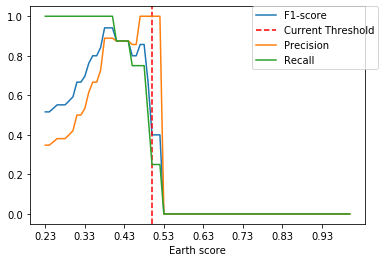

In [0]:
th = 0.5
id_th = np.argmin(np.abs((thresholds - th)))

print(f"Metrics for {th:.1f}:")
print(f"Precision >> {results_p[id_th]:.3f}")
print(f"Recall    >> {results_r[id_th]:.3f}")
print(f"F1 Score  >> {results_f[id_th]:.3f}")

plt.plot(results_f, label='F1-score')
plt.axvline([id_th],ymin=0.0, ymax=1, c="r", label="Current Threshold", linestyle="--")
plt.plot(results_p, label='Precision')
plt.plot(results_r, label='Recall')
plt.xticks(range(0,len(thresholds),10), [f'{float(f):.2f}' for f in thresholds[::10]])
plt.xlabel("Earth score")
plt.legend(bbox_to_anchor=(1.04,1), borderaxespad=0)

Podemos apreciar que quizás no elegimos el mejor threshold posible, pero claramente esto solo para los datos que analizamos. Lo que habría que hacer es una vez elegido un threshold generar un segundo dataset y corroborar que dicho threshold sigue siendo válido para los nuevos datos, mientras más lo probemos en gran diversidad de conjunto de imágenes más seguro estaremos de la performance del modelo para datos no vistos.

## Revisión de malos resultados

Generalmente uno cuando termina de evaluar el modelo también revisa los casos en que se equivocó, y puede tratar de intentar entender las cuestiones que están haciendo confundir al modelo, generalmente identificar estos aspectos no es algo trivial.

La vida de un modelo es un ciclo continuo de entrenamiento donde a medida que voy obteniendo malos resultados los utilizo en una siguiente iteración de entrenamiento para mejorar mi modelo, pero esto a su vez puede generar que se equivoque en otro tipo de imágenes que quizás no se equivocaba... en definitiva la teoría dice que en algún punto deberíamos alcanzar un equilibrio en el cual el modelo se estabiliza.

La etiqueta es 'earth' pero se predijo lo contrario


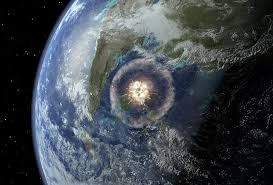

In [0]:
# importamos lo necesario para poder desplegar imágenes
from IPython.core.display import Image, display
from os.path import dirname, basename


idxs = eval_Xs != eval_Ys
for f, idx in zip(files[idxs], idxs):
    folder = basename(dirname(f))
    print(f"La etiqueta es '{folder}' pero se predijo lo contrario")
    display(Image(f, width=160, height=160, unconfined=True))